In [4]:
# Customer Segmentation

In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt



In [2]:
data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data_cleaned+scaled.csv',encoding='ISO-8859-1')

In [3]:
customer_df = data.groupby('CustomerID').agg({
    # dépenses 
    'TotalSpent': 'sum',
    'NumTransactions': 'sum',
    'AvgTransactionValue': 'mean',
    'MaxTransactionValue': 'max',
    'TotalPrice': 'sum',
    'AvgPricePerItem': 'mean',
    'AvgUnitPriceSold': 'mean',
    'TotalQuantity': 'sum',
    'Quantity': 'sum',
    'AvgItemsPerTransaction': 'mean',
    'NumUniqueItemsBought': 'sum',
    'CustomerProductAffinity': 'mean',
    
    # RFM 
    'RecencyDays': 'mean',
    'FrequencyPerMonth': 'mean',
    'MonetaryPerMonth': 'mean',
    'AvgDaysBetweenInvoices': 'mean',
    'TenureDays': 'mean',
    'TenureMonths': 'mean',
    'Recency_x_Frequency': 'mean',
    'Frequency_x_Monetary': 'mean',

    # retour et satisfaction
    'ReturnRate': 'mean',
    'SentimentScore': 'mean',
    'AvgSentimentScore': 'mean',
    'IsDeluxe': 'mean',

    # saisonnalité
    'InvoiceMonth': lambda x: x.mode()[0],
    'InvoiceQuarter': lambda x: x.mode()[0],
    'InvoiceDayOfWeek': lambda x: x.mode()[0],
    'InvoiceHour': lambda x: x.mode()[0],
    'IsWeekend': 'mean',
    'IsHolidaySeason': 'mean',

    # géographie
    'CountryAvgSpend': 'mean',
    'CountryAvgSpendDeviation': 'mean',

    # dates clés
    'FirstPurchase_Year': 'min',
    'FirstPurchase_Month': 'min',
    'FirstPurchase_Day': 'min',
    'FirstPurchase_Hour': 'min',
    'LastPurchase_Year': 'max',
    'LastPurchase_Month': 'max',
    'LastPurchase_Day': 'max',
    'LastPurchase_Hour': 'max',
    
}).reset_index()


In [4]:
features = [
    
    'TotalSpent',
    'NumTransactions',
    'AvgTransactionValue',
    'MaxTransactionValue',
    'TotalQuantity',
    'AvgItemsPerTransaction',
    'NumUniqueItemsBought',
    'CustomerProductAffinity',
    
    
    'RecencyDays',
    'FrequencyPerMonth',
    'MonetaryPerMonth',
    'AvgDaysBetweenInvoices',
    'TenureDays',
    'TenureMonths',
    'Recency_x_Frequency',
    'Frequency_x_Monetary',
    
    
    'ReturnRate',
    'SentimentScore',
    'AvgSentimentScore',
    'IsDeluxe',
    

    'InvoiceMonth',
    'InvoiceQuarter',
    'InvoiceDayOfWeek',
    'InvoiceHour',
    'IsWeekend',
    'IsHolidaySeason',
    
    
    'CountryAvgSpendDeviation'
]


X = customer_df[features]


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.graph_objects as go


scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)  
    score = silhouette_score(X, kmeans.labels_)
    scores.append(score)


optimal_k = K_range[np.argmax(scores)]
optimal_score = max(scores)

fig = go.Figure()


fig.add_trace(go.Scatter(
    x=list(K_range),
    y=scores,
    mode='lines+markers',
    name='Silhouette Score',
    line=dict(color='royalblue', width=3),
    marker=dict(size=8)
))


fig.add_trace(go.Scatter(
    x=[optimal_k],
    y=[optimal_score],
    mode='markers+text',
    name=f'K optimal = {optimal_k}',
    text=[f'K={optimal_k}'],
    textposition="top center",
    marker=dict(color='red', size=12, symbol='x')
))


fig.update_layout(
    title="📈 Silhouette Score selon le nombre de clusters (K)",
    xaxis_title="Nombre de clusters (K)",
    yaxis_title="Silhouette Score",
    template="plotly_white",
    font=dict(size=14),
    showlegend=True
)

fig.show()

print(f"K optimal = {optimal_k} avec un score de silhouette de {optimal_score:.3f}")


K optimal = 2 avec un score de silhouette de 0.995


In [6]:
optimal_k = 2  
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
customer_df['Cluster'] = kmeans.fit_predict(X)


In [7]:
cluster_profile = customer_df.groupby('Cluster')[features].mean().round(2)
print(cluster_profile)


         TotalSpent  NumTransactions  AvgTransactionValue  \
Cluster                                                     
0              4.59             4.79                 0.37   
1           3204.22          5079.05                 0.34   

         MaxTransactionValue  TotalQuantity  AvgItemsPerTransaction  \
Cluster                                                               
0                       0.49          23.22                    0.56   
1                       0.90        1587.23                    0.47   

         NumUniqueItemsBought  CustomerProductAffinity  RecencyDays  \
Cluster                                                               
0                        8.98                     0.19         0.24   
1                     5363.19                     0.01         0.00   

         FrequencyPerMonth  ...  SentimentScore  AvgSentimentScore  IsDeluxe  \
Cluster                     ...                                                
0                     0.0

In [8]:
import plotly.express as px

fig = px.imshow(cluster_profile.T, text_auto=True, 
                color_continuous_scale='Blues',
                title="Profil des segments clients",
               width=1200,                         
               height=900  )
fig.show()


In [9]:
import plotly.express as px

for col in ['TotalSpent', 'AvgTransactionValue', 'RecencyDays', 'FrequencyPerMonth', 'ReturnRate']:
    fig = px.box(customer_df, x='Cluster', y=col, color='Cluster',
                 title=f'Distribution de {col} par Cluster',
                 template='plotly_white')
    fig.show()


In [10]:
from sklearn.preprocessing import MinMaxScaler
import plotly.graph_objects as go

scaler = MinMaxScaler()
cluster_norm = pd.DataFrame(
    scaler.fit_transform(cluster_profile),
    columns=cluster_profile.columns,
    index=cluster_profile.index
)

# radar chart
categories = cluster_norm.columns
fig = go.Figure()

for i in cluster_norm.index:
    fig.add_trace(go.Scatterpolar(
        r=cluster_norm.loc[i].values,
        theta=categories,
        fill='toself',
        name=f'Cluster {i}'
    ))

fig.update_layout(
    polar=dict(radialaxis=dict(visible=True)),
    title="🌐 Profil comparatif des clusters (Radar chart)",
    template="plotly_white"
)
fig.show()


In [11]:
fig = px.scatter_3d(customer_df, 
                    x='FrequencyPerMonth', 
                    y='MonetaryPerMonth', 
                    z='RecencyDays',
                    color='Cluster',
                    title='Segmentation clients - Vue 3D (RFM)',
                    template='plotly_white')
fig.show()


In [12]:
fig = px.scatter(customer_df, 
                 x='SentimentScore', 
                 y='TotalSpent', 
                 color='Cluster',
                 size='NumTransactions',
                 hover_data=['AvgTransactionValue'],
                 title='Sentiment client vs Dépense totale',
                 template='plotly_white')
fig.show()


In [13]:
cluster_sales = customer_df.groupby('Cluster')['TotalSpent'].sum().reset_index()
fig = px.pie(cluster_sales, values='TotalSpent', names='Cluster', 
             title='Répartition du chiffre d’affaires par cluster',
             color_discrete_sequence=px.colors.qualitative.Set3)
fig.show()


In [14]:
fig = px.histogram(customer_df, x='RecencyDays', color='Cluster',
                   nbins=30, barmode='overlay',
                   title='Distribution de la récence par cluster',
                   template='plotly_white')
fig.show()


In [15]:
summary = cluster_profile.copy()
summary['Insight'] = summary.apply(lambda row:
    "Premium clients (High spend, frequent)" if row['TotalSpent'] > summary['TotalSpent'].mean() and row['FrequencyPerMonth'] > summary['FrequencyPerMonth'].mean()
    else "Occasional buyers" if row['FrequencyPerMonth'] < summary['FrequencyPerMonth'].mean()
    else "Inactive customers" if row['RecencyDays'] > summary['RecencyDays'].mean()
    else "Loyal mid-spenders", axis=1)

summary[['Insight']]


,Insight
Cluster,
0,Occasional buyers
1,"Premium clients (High spend, frequent)"


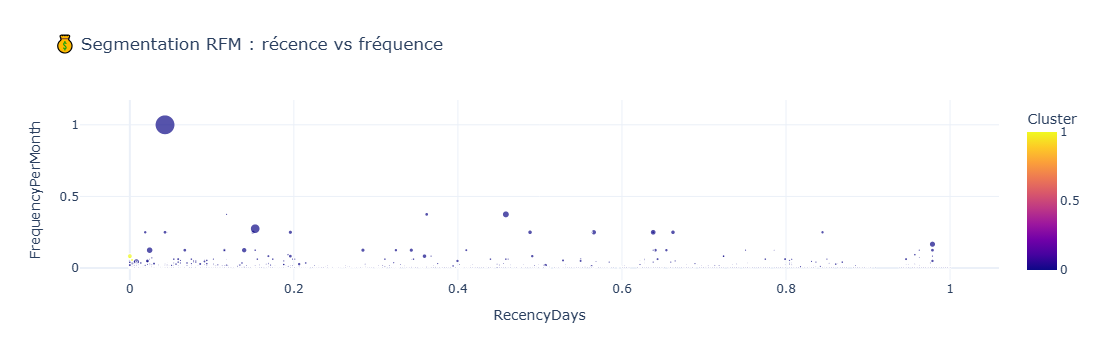

In [16]:
fig = px.scatter(customer_df, 
                 x='RecencyDays', 
                 y='FrequencyPerMonth', 
                 color='Cluster',
                 size='MonetaryPerMonth',
                 hover_data=['TotalSpent'],
                 title='💰 Segmentation RFM : récence vs fréquence',
                 template='plotly_white')
fig.show()


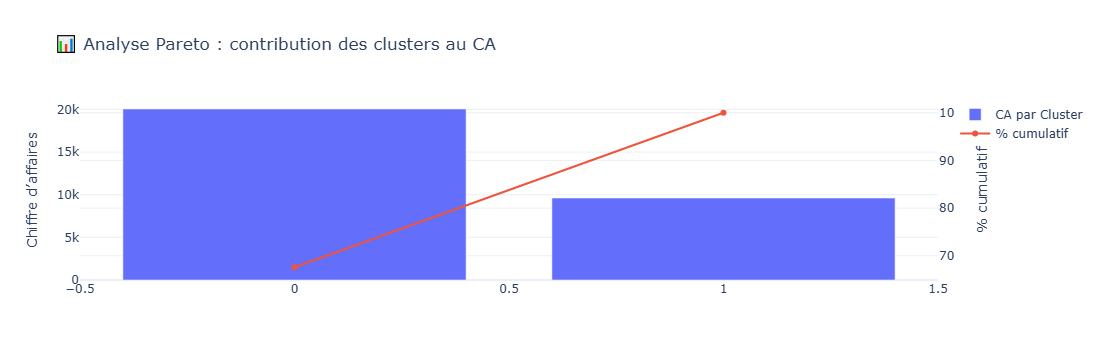

In [17]:
pareto = cluster_sales.sort_values('TotalSpent', ascending=False)
pareto['Cumulative%'] = pareto['TotalSpent'].cumsum() / pareto['TotalSpent'].sum() * 100

fig = go.Figure()
fig.add_trace(go.Bar(x=pareto['Cluster'], y=pareto['TotalSpent'], name='CA par Cluster'))
fig.add_trace(go.Scatter(x=pareto['Cluster'], y=pareto['Cumulative%'], 
                         mode='lines+markers', name='% cumulatif', yaxis='y2'))

fig.update_layout(
    title="📊 Analyse Pareto : contribution des clusters au CA",
    yaxis=dict(title='Chiffre d’affaires'),
    yaxis2=dict(title='% cumulatif', overlaying='y', side='right'),
    template='plotly_white'
)
fig.show()


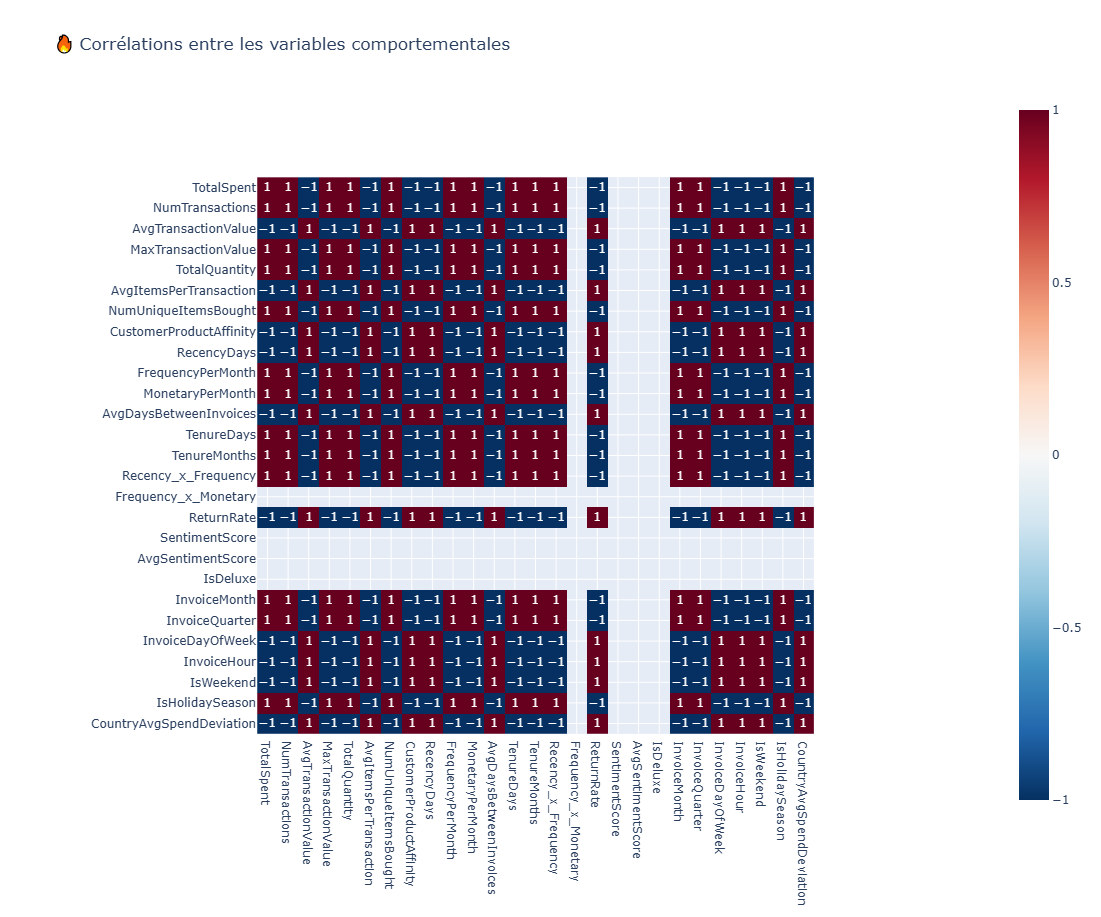

In [18]:
corr = cluster_profile.corr()
fig = px.imshow(corr, text_auto=True, color_continuous_scale='RdBu_r',
                title="🔥 Corrélations entre les variables comportementales",
                width=1200,                         
                height=900  )
fig.show()


# 🎯 Customer Segmentation Report 

We analyzed our customer base and identified **2 main clusters**. This segmentation provides actionable marketing insights tailored to each group's behavior.

---

## 🧩 **Cluster Overview**

| Cluster | Label | Characteristics |
|---------|-------|----------------|
| 0 | Occasional Buyers | Customers who buy frequently but prefer cheaper products. Lower engagement overall. |
| 1 | Premium Product Buyers | Customers who buy high-end or deluxe products but have low overall engagement and purchase frequency. |

---

## 📊 **Cluster Insights & Marketing Advice**

### **Cluster 0 — Occasional Buyers (Cheaper Products)**
**Insights:**
- Lower total spending per transaction.  
- Purchase smaller, less expensive items.  
- Moderate engagement — they can become loyal if incentivized.  

**Marketing Advice:**
- 🛍️ Promote budget-friendly bundles or frequent deals.  
- 🎁 Introduce loyalty points to encourage repeat purchases.  
- 📅 Run campaigns highlighting affordable new arrivals or seasonal discounts.  
- 💌 Use reminders and newsletters to increase engagement.

---

### **Cluster 1 — Premium Product Buyers (Low Engagement)**
**Insights:**
- Prefer high-end or deluxe products.  
- Low purchase frequency — engagement is limited.  
- High-value potential, but not regular shoppers.  

**Marketing Advice:**
- 🏆 Offer exclusive access to premium products or VIP events.  
- 🎯 Personalize recommendations based on previous deluxe purchases.  
- 💌 Send targeted campaigns to re-engage them, e.g., limited-time premium offers.  
- 📈 Encourage subscription models or high-value bundles to increase purchase frequency.

---

##  **Summary**
- **Cluster 0:** Focus on boosting engagement with affordable products.  
- **Cluster 1:** Focus on retention and re-engagement for high-value premium customers.  

---

> **Conclusion:**  
> This segmentation allows marketing teams to **strategically target offers**: drive engagement among occasional buyers while nurturing premium product buyers to increase their frequency.
